In [82]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from random import shuffle

In [120]:
r_scape = pickle.load(open("data/eval_rscape.pickle", "rb"))
phylo_score = pickle.load(open("data/eval_phyloscore_tmp.pickle", "rb"))
datasets = list(map(str.strip, open("3d.txt", "r")))

In [121]:
r_scape[("RF00026", "GTp")]

(1.0, 1.0)

In [122]:
def extract_hyperparameters(dict):
    keys = [k[1:] for k in dict.keys()]
    return set(keys)

In [123]:
def best_hyper(dict, train_set):
    best_score = -1
    best_hyperparameters = None
    for hyper in extract_hyperparameters(dict):
        score = 0
        for dataset in train_set:
            score += dict[(dataset, *hyper)][1]
        
        if score > best_score:
            best_score = score
            best_hyperparameters = hyper
    return best_hyperparameters

In [124]:
best_hyper(phylo_score, datasets)

('0.5', '0.01', 'optdiff', 'APC')

In [107]:
def cross_validation(data, per_dataset_results : dict, splits=5):
    local_datasets = list(datasets)
    # shuffle the datasets
    shuffle(local_datasets)

    #split in splits folds
    numpy = np.array(local_datasets)
    folds = np.array_split(numpy, splits)

    results = []
    for i in range(splits):
        test = set(folds[i])
        train = set(numpy) - test

        best_hyperparameters = best_hyper(data, train)
        print(f"Best hyperparameters for fold {i}: {best_hyperparameters}")
        print("RF00026" in test)
        for dataset in test:
            results.append(data[(dataset, *best_hyperparameters)][1])
            if dataset not in per_dataset_results:
                per_dataset_results[dataset] = []
            per_dataset_results[dataset].append(data[(dataset, *best_hyperparameters)][1])
        
    return np.mean(results) * 100

In [108]:
per_dataset_dict = {}
cross_validation(phylo_score, per_dataset_dict)

Best hyperparameters for fold 0: ('0.5', '0.0', 'optdiff', 'APC')
True
Best hyperparameters for fold 1: ('0.5', '0.0', 'optdiff', 'APC')
False
Best hyperparameters for fold 2: ('0.5', '0.0', 'optdiff', 'APC')
False
Best hyperparameters for fold 3: ('0.5', '0.0', 'optdiff', 'APC')
False
Best hyperparameters for fold 4: ('0.5', '0.0', 'optdiff', 'APC')
False


np.float64(71.44816644002383)

In [109]:
rscape_per_dataset = {}
phylo_score_per_dataset = {}
results_rscape = [cross_validation(r_scape, rscape_per_dataset) for _ in range(1000)]
results_phyloscore = [cross_validation(phylo_score, phylo_score_per_dataset) for _ in range(1000)]

Best hyperparameters for fold 0: ('GTp',)
False
Best hyperparameters for fold 1: ('GTp',)
False
Best hyperparameters for fold 2: ('GTp',)
False
Best hyperparameters for fold 3: ('GTp',)
True
Best hyperparameters for fold 4: ('GTp',)
False
Best hyperparameters for fold 0: ('GTp',)
False
Best hyperparameters for fold 1: ('GTp',)
True
Best hyperparameters for fold 2: ('GTp',)
False
Best hyperparameters for fold 3: ('GTp',)
False
Best hyperparameters for fold 4: ('GTp',)
False
Best hyperparameters for fold 0: ('GTp',)
False
Best hyperparameters for fold 1: ('GTp',)
False
Best hyperparameters for fold 2: ('GTp',)
False
Best hyperparameters for fold 3: ('GTp',)
True
Best hyperparameters for fold 4: ('GTp',)
False
Best hyperparameters for fold 0: ('GTp',)
False
Best hyperparameters for fold 1: ('GTp',)
True
Best hyperparameters for fold 2: ('GTp',)
False
Best hyperparameters for fold 3: ('GTp',)
False
Best hyperparameters for fold 4: ('GTp',)
False
Best hyperparameters for fold 0: ('GTp',)
Fa

In [90]:
rscape_per_dataset["RF00026"]

[0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7380952380952381,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7380952380952381,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 1.0,
 0.7254901960784312,
 1.0,
 0.7254901960784312,
 1.0,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7380952380952381,
 0.7254901960784312,
 0.7254901960784312,
 1.0,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7380952380952381,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7380952380952381,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 0.7254901960784312,
 1.0,
 0.7254901960784312,
 0.7380952380952381,
 0.7254901960784312,
 0.7380952380952381,
 0.7

In [110]:
def box_plot(data_dict):
    categories = list(data_dict.keys())
    means = [np.mean(data_dict[cat]) for cat in categories]
    stds = [np.std(data_dict[cat]) for cat in categories]

    # Create bar plot with error bars
    plt.figure(figsize=(10, 6))
    plt.bar(categories, means, yerr=stds, capsize=10, color='skyblue', 
            edgecolor='black', alpha=0.7)

    plt.title('Bar Plot with Error Bars (Standard Deviation)')
    plt.ylabel('Mean Values')
    plt.xlabel('Categories')
    plt.grid(True, alpha=0.3, axis='y')
    plt.show()

In [111]:
def plot_side_by_side_barplot(dict1, dict2, label1='Dataset 1', label2='Dataset 2', 
                               error_type='std', figsize=(12, 6)):
    """
    Create side-by-side bar plot comparing two dictionaries.
    
    Parameters:
    -----------
    dict1, dict2 : dict
        Dictionaries with keys as categories and values as lists of floats
    label1, label2 : str
        Labels for the two datasets
    error_type : str
        Type of error bars: 'std' (standard deviation), 'sem' (standard error), 
        'ci95' (95% confidence interval), or None
    figsize : tuple
        Figure size (width, height)
    """
    # Get common categories (keys present in both dictionaries)
    categories = sorted(set(dict1.keys()) | set(dict2.keys()))
    
    # Calculate statistics for dict1
    means1 = []
    errors1 = []
    for cat in categories:
        if cat in dict1:
            data = dict1[cat]
            means1.append(np.mean(data))
            if error_type == 'std':
                errors1.append(np.std(data))
            elif error_type == 'sem':
                errors1.append(np.std(data) / np.sqrt(len(data)))
            elif error_type == 'ci95':
                sem = np.std(data) / np.sqrt(len(data))
                ci = sem * 1.96  # 95% confidence interval
                errors1.append(ci)
            else:
                errors1.append(0)
        else:
            means1.append(0)
            errors1.append(0)
    
    # Calculate statistics for dict2
    means2 = []
    errors2 = []
    for cat in categories:
        if cat in dict2:
            data = dict2[cat]
            means2.append(np.mean(data))
            if error_type == 'std':
                errors2.append(np.std(data))
            elif error_type == 'sem':
                errors2.append(np.std(data) / np.sqrt(len(data)))
            elif error_type == 'ci95':
                sem = np.std(data) / np.sqrt(len(data))
                ci = sem * 1.96
                errors2.append(ci)
            else:
                errors2.append(0)
        else:
            means2.append(0)
            errors2.append(0)
    
    # Create plot
    x = np.arange(len(categories))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create bars
    bars1 = ax.bar(x - width/2, means1, width, yerr=errors1, 
                   capsize=2, label=label1, color='skyblue', 
                   edgecolor='black', alpha=0.7)
    bars2 = ax.bar(x + width/2, means2, width, yerr=errors2, 
                   capsize=2, label=label2, color='lightcoral', 
                   edgecolor='black', alpha=0.7)
    
    # Customize plot
    ax.set_xlabel('Categories', fontsize=12)
    ax.set_ylabel('Values', fontsize=12)
    ax.set_title(f'Side-by-Side Comparison: {label1} vs {label2}', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(categories, rotation=90)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    return fig, ax

In [112]:
def scatter_compare_with_diagonal(dict1, dict2, label1='Dataset 1', label2='Dataset 2',
                                   error_type='sem', figsize=(8, 8)):
    """
    Create scatter plot comparing two dictionaries with diagonal line.
    
    Parameters:
    -----------
    dict1, dict2 : dict
        Dictionaries with same keys and lists of floats as values
    label1, label2 : str
        Labels for axes
    error_type : str or None
        'std', 'sem', 'ci95', or None for error bars
    figsize : tuple
        Figure size (square recommended)
    """
    # Get common categories
    common_keys = sorted(set(dict1.keys()) & set(dict2.keys()))
    
    if not common_keys:
        raise ValueError("Dictionaries have no common keys")
    
    # Calculate means and errors
    means1 = []
    means2 = []
    errors1 = []
    errors2 = []
    
    for key in common_keys:
        data1 = dict1[key]
        data2 = dict2[key]
        
        mean1 = np.mean(data1)
        mean2 = np.mean(data2)
        means1.append(mean1)
        means2.append(mean2)
        
        if error_type == 'std':
            errors1.append(np.std(data1))
            errors2.append(np.std(data2))
        elif error_type == 'sem':
            errors1.append(np.std(data1) / np.sqrt(len(data1)))
            errors2.append(np.std(data2) / np.sqrt(len(data2)))
        elif error_type == 'ci95':
            sem1 = np.std(data1) / np.sqrt(len(data1))
            sem2 = np.std(data2) / np.sqrt(len(data2))
            errors1.append(sem1 * 1.96)
            errors2.append(sem2 * 1.96)
        else:
            errors1.append(0)
            errors2.append(0)
    
    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    
    # Add diagonal line (y=x)
    min_val = min(min(means1), min(means2))
    max_val = max(max(means1), max(means2))
    margin = (max_val - min_val) * 0.1
    ax.plot([min_val - margin, max_val + margin], 
            [min_val - margin, max_val + margin], 
            'k--', alpha=0.5)
    
    # Add error bars (horizontal and vertical)
    if error_type:
        ax.errorbar(means1, means2, 
                   xerr=errors1, yerr=errors2,
                   fmt='o', capsize=5, capthick=1, elinewidth=1,
                   color='blue', alpha=0.7, markersize=8,
                   label=f'{label1} vs {label2}')
    else:
        ax.scatter(means1, means2, color='blue', alpha=0.7, s=80,
                  label=f'{label1} vs {label2}')
    
    # Customize plot
    ax.set_xlabel(f'{label1} (Mean Values)', fontsize=12)
    ax.set_ylabel(f'{label2} (Mean Values)', fontsize=12)
    ax.set_title(f'Scatter Plot Comparison: {label1} vs {label2}', fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best')
    ax.set_aspect('equal')
    
    # Set limits with equal ranges
    all_vals = means1 + means2
    min_val = min(all_vals) - margin
    max_val = max(all_vals) + margin
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    
    plt.tight_layout()
    return fig, ax

(<Figure size 1200x600 with 1 Axes>,
 <Axes: title={'center': 'Side-by-Side Comparison: R-scape vs PhyloScore'}, xlabel='Categories', ylabel='Values'>)

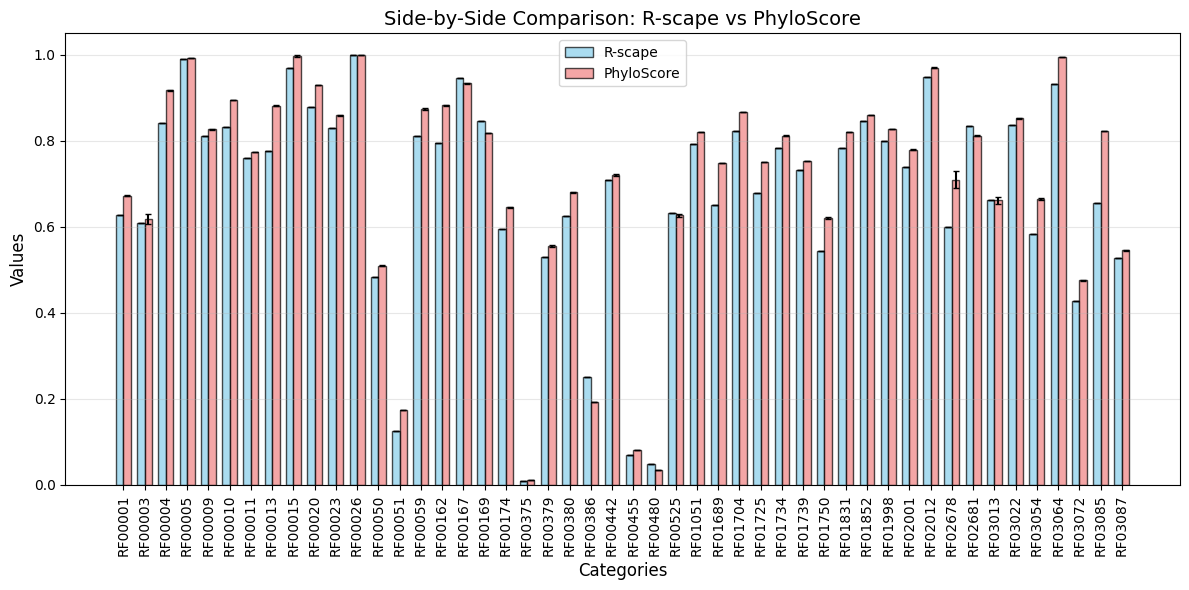

In [113]:
plot_side_by_side_barplot(rscape_per_dataset, phylo_score_per_dataset, label1='R-scape', label2='PhyloScore', error_type='std')

(<Figure size 800x800 with 1 Axes>,
 <Axes: title={'center': 'Scatter Plot Comparison: R-scape vs PhyloScore'}, xlabel='R-scape (Mean Values)', ylabel='PhyloScore (Mean Values)'>)

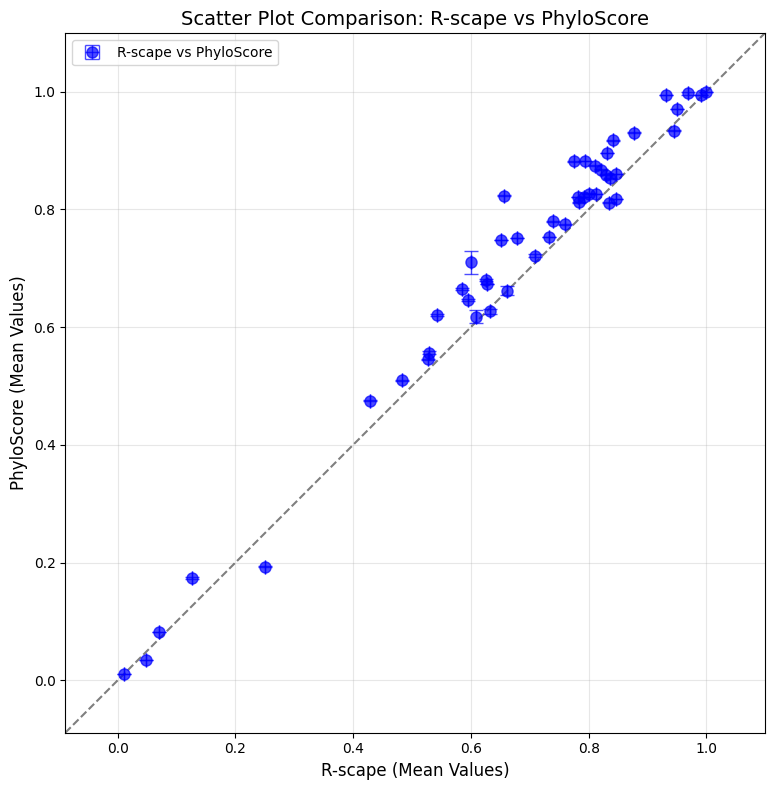

In [114]:
scatter_compare_with_diagonal(rscape_per_dataset, phylo_score_per_dataset, label1='R-scape', label2='PhyloScore', error_type='std')

(array([  2.,   0.,   0.,   1.,   1.,   0.,   2.,   0.,   1.,   1.,   1.,
          1.,   1.,   4.,   1.,   3.,   1.,   2.,   6.,   3.,   3.,   3.,
          5.,   5.,   2.,   2.,   5.,   8.,   9.,   5.,   4.,   5.,  14.,
          9.,   3.,   7.,  11.,  13.,  16.,  13.,   2.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
        825.]),
 array([71.15404386, 71.15698508, 71.15992631, 71.16286754, 71.16580876,
        71.16874999, 71.17169121, 71.17463244, 71.17757367, 71.18051489,
        71.18345612, 71.18639734, 71.18933857, 71.19227979, 71.19522102,
        71.19816225, 71.20110347, 71.2040447 , 71.20698592, 71.20992715,
        71.21286837, 71.21

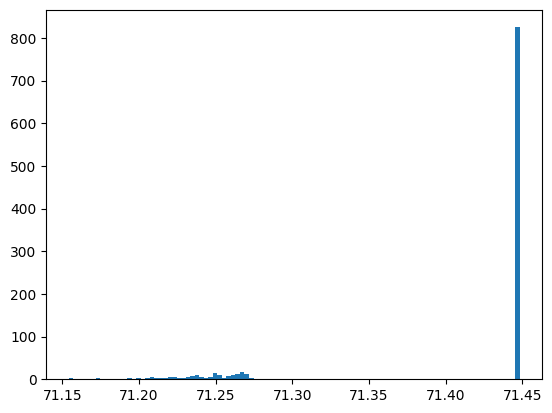

In [118]:
plt.hist(results_phyloscore, bins=100)

In [116]:
results_rscape

[np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.87249395707249),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.87249395707249),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.87249395707249),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.float64(67.8724939570725),
 np.f

In [117]:
results_phyloscore

[np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.1930575766524),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.25114344126864),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002381),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.44816644002383),
 np.float64(71.25177726007168),
 np.float

In [99]:
np.mean([r_scape[(dataset, "GTp")][1] for dataset in datasets]) * 100

np.float64(67.8724939570725)

In [125]:
np.mean([phylo_score[(dataset, '0.5', '0.01', "optdiff", "APC")][1] for dataset in datasets]) * 100

np.float64(71.47547338347354)

In [ ]:

sort_scores = np.sort(scores)

L = reverse_triangle_number(len(scores)) + 1

# Remove L//2 highest scores, because they might be positive
sort_scores = sort_scores[:-(L // 2)]


fit = scipy.stats.gamma.fit(sort_scores, method='mm')